# Sparse regression with feasible dual bounds

ISTA, FISTA and ADMM solve the same convex objective. A dual-feasible residual gives a real suboptimality bound. ADMM factorization and gradient iterations have different costs.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Closed-form oracle

In [2]:
from optimization_lab.first_order import lasso
b=np.array([3.,-2.,.25])
for method in ["ista","fista","admm"]:
    result=lasso(np.eye(3),b,1.,method)
    assert np.allclose(result["x"],[2.,-1.,0.],atol=1e-6)
    print(method,result["certificate"])

ista {'objective': 4.03125, 'dual_objective': 4.031249999997, 'gap': 3.000266701747023e-12, 'dual_feasibility': -1.000088900582341e-12}
fista {'objective': 4.03125, 'dual_objective': 4.031249999997, 'gap': 3.000266701747023e-12, 'dual_feasibility': -1.000088900582341e-12}
admm {'objective': 4.031250000000023, 'dual_objective': 4.031249940392363, 'gap': 5.960766014112551e-08, 'dual_feasibility': -1.000088900582341e-12}


## All seeds

In [3]:
rows=[]
for seed in [0,1,2]:
    for row in read(f"results/reference/first_order/lasso_seed{seed}/metrics.json")["rows"]:
        rows.append(dict(seed=seed,method=row["method"],iterations=row["iterations"],**row["certificate"]))
pd.DataFrame(rows)

,seed,method,iterations,objective,dual_objective,gap,dual_feasibility
0,0,ista,1912,3.354510,3.354510,9.953268e-08,-1.500744e-13
1,0,fista,1767,3.354510,3.354510,9.277236e-08,-1.499911e-13
2,0,admm,157,3.354510,3.354510,9.644035e-08,-1.499634e-13
3,1,ista,1759,3.229253,3.229253,9.908794e-08,-1.500466e-13
4,1,fista,1425,3.229253,3.229253,8.183651e-08,-1.500189e-13
5,1,admm,151,3.229253,3.229253,9.187039e-08,-1.500189e-13
6,2,ista,2932,2.898873,2.898873,9.981373e-08,-1.500466e-13
7,2,fista,1899,2.898873,2.898873,1.719120e-08,-1.499911e-13
8,2,admm,216,2.898873,2.898873,9.248469e-08,-1.499911e-13


## Iteration and time

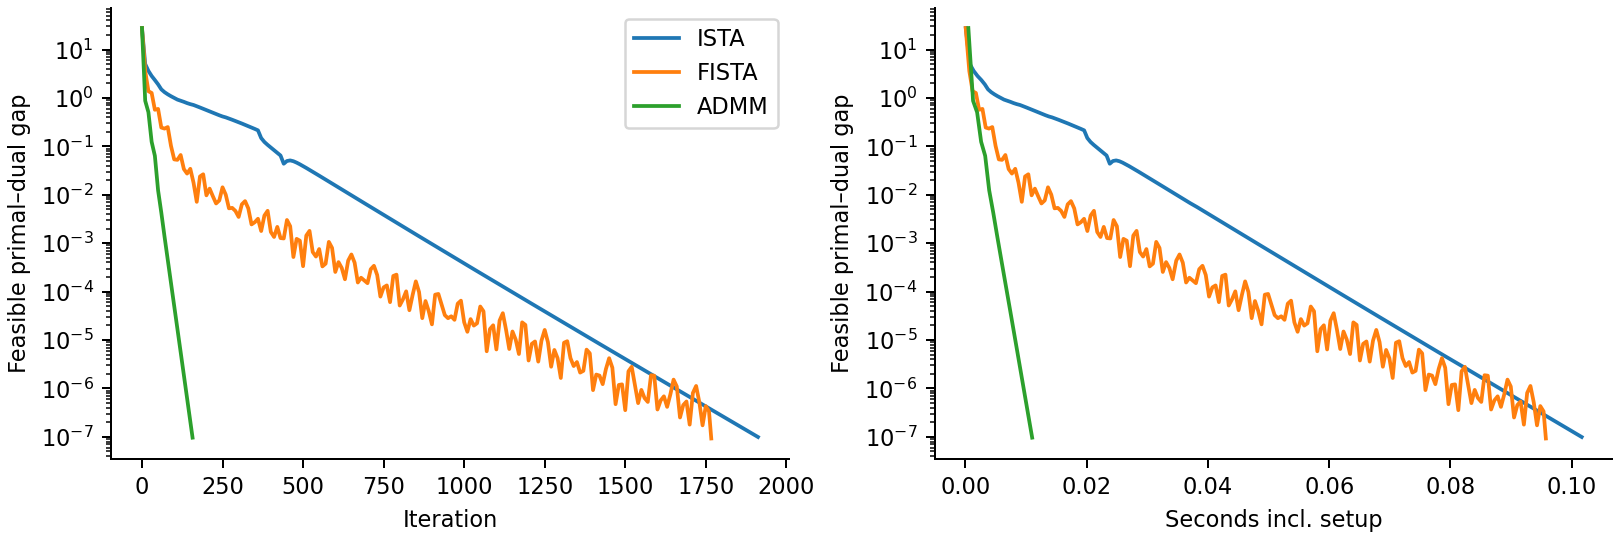

In [4]:
figure("lasso_convergence_seed0")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.